## LangChain + LangGraph 멀티 에이전트 실전 예제

하나의 LLM이 모든 일을 처리하는 대신, **역할이 나뉜 여러 에이전트가 협업**하도록 설계하는 방법을 다섯 개의 예제로 단계적으로 경험합니다.

| 단계 | 예제 | 핵심 패턴 | 꼭 알아야 할 개념 |
|---|---|---|---|
| 기초 | ① 리서처 → 작성자 | 순차 협업 (Pipeline) | 공유 State, 역할별 프롬프트, 모델 분업 |
| 기초 | ② 질문 라우터 | 분기 (Router) | 구조화 출력, 조건부 엣지 |
| 중급 | ③ 감독자와 도구 에이전트 | 감독자 (Supervisor) | `create_agent`, 도구 호출, `Command` 핸드오프, 루프 제한 |
| 중급 | ④ 다관점 병렬 리뷰 | 병렬 분산·집계 (Map-Reduce) | `Send`, 리듀서(`operator.add`) |
| 고급 | ⑤ 작성자·비평가 + 사람 승인 | 자기 개선 루프 + HITL | 체크포인터, `interrupt`, `RetryPolicy`, 스트리밍 |
| 정리 | `create_agent` + 미들웨어 vs LangGraph | 도구 선택 기준 | 미들웨어의 범위와 한계, 판단 기준 |

**사용 모델**
- `gpt-4o-mini` (OpenAI): 판단·분류·도구 호출처럼 **형식이 정확해야 하는 역할**
- `gemini-3.5-flash-lite` (Google): 글쓰기·관점 제시처럼 **생성량이 많은 역할**

> 서로 다른 회사의 모델을 섞어 쓰면 비용을 줄이고, 한 모델의 편향을 다른 모델이 보완하게 할 수 있습니다. 멀티 에이전트의 실무적인 장점 중 하나입니다.

각 예제의 마지막 셀에서는 완성된 **노드 워크플로우를 이미지로 출력**합니다.

> **한눈에 보기**
> - 멀티 에이전트 패턴 5가지: ① 순차(리서처 → 작성자) ② 라우터 ③ 감독자 + `create_agent` 하위 에이전트(`Command`) ④ Map-Reduce(`Send`) ⑤ 작성자·비평가 루프 + 사람 승인(`interrupt`)
> - 각 노드가 무엇을 보게 할지(컨텍스트 설계)가 핵심: 작성자는 리서처 결과만, 하위 에이전트는 감독자의 작업 지시만 받는다
> - `create_agent` + 미들웨어로 되는 범위(`jump_to`: tools·model·end)와 LangGraph가 필요해지는 경우 비교
> - 정리 문서: [멀티에이전트패턴.md](멀티에이전트패턴.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

### 0. 환경 준비

**실행 환경**: Python 3.12

수업 재현성을 위해 패키지 버전을 고정합니다 (2026년 10월 기준 최신 버전).

In [1]:
'''
%pip install -q \
    langchain==1.4.7 \
    langchain-core==1.7.0 \
    langgraph==1.2.17 \
    langchain-openai==1.7.2 \
    langchain-google-genai==4.4.2 \
    python-dotenv==1.2.4
    '''

'\n%pip install -q     langchain==1.4.7     langchain-core==1.7.0     langgraph==1.2.17     langchain-openai==1.7.2     langchain-google-genai==4.4.2     python-dotenv==1.2.4\n    '

In [2]:
import os

# 키가 제대로 로드되었는지 확인 (값 자체는 출력하지 않습니다)
for key in ["OPENAI_API_KEY", "GEMINI_API_KEY"]:
    print(f"{key}: {'✅ 설정됨' if os.getenv(key) else '❌ 없음'}")

OPENAI_API_KEY: ✅ 설정됨
GEMINI_API_KEY: ✅ 설정됨


#### 공통 모델과 헬퍼 함수

- 두 모델 객체를 한 번만 만들어 모든 예제에서 재사용합니다.
- `show_graph()`는 컴파일된 그래프를 PNG 이미지로 출력합니다. 이미지 렌더링은 mermaid.ink 웹 서비스를 사용하므로, 인터넷이 막힌 환경에서는 Mermaid 텍스트로 대신 출력합니다.

In [3]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from IPython.display import Image, display

# 형식이 정확해야 하는 역할 (판단, 분류, 도구 호출)
gpt = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# 생성량이 많은 역할 (글쓰기, 관점 제시)
gemini = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")


def show_graph(app):
    # 컴파일된 그래프의 노드 워크플로우를 이미지로 출력합니다
    try:
        display(Image(app.get_graph(xray=True).draw_mermaid_png()))
    except Exception as e:
        print(f"[이미지 렌더링 실패 → Mermaid 텍스트로 출력] {e}\n")
        print(app.get_graph(xray=True).draw_mermaid())


# 간단한 동작 확인
print("gpt    :", gpt.invoke("한 단어로 인사해줘").text)
print("gemini :", gemini.invoke("한 단어로 인사해줘").text)

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


gpt    : 안녕하세요!
gemini : 안녕!


> **💡 `.text` 를 쓰는 이유**
> Gemini 응답의 `content`는 문자열이 아니라 **블록 리스트**로 올 때가 있습니다. `message.text`는 모델 종류와 상관없이 텍스트만 꺼내 주므로, 여러 회사 모델을 섞는 멀티 에이전트 코드에서는 `.content` 대신 `.text`를 쓰는 습관이 안전합니다.

---
### [기초] 예제 ① 리서처 → 작성자 : 순차 협업 
멀티 스텝 LLM 파이프라인(Multi-step LLM Pipeline)

### 시나리오
사용자가 주제를 주면,
1. **리서처 노드** (`gpt-4o-mini`)가 핵심 사실을 bullet 로 정리하고
2. **작성자 노드** (`gemini-3.5-flash-lite`)가 그 자료만 보고 블로그 글을 씁니다.

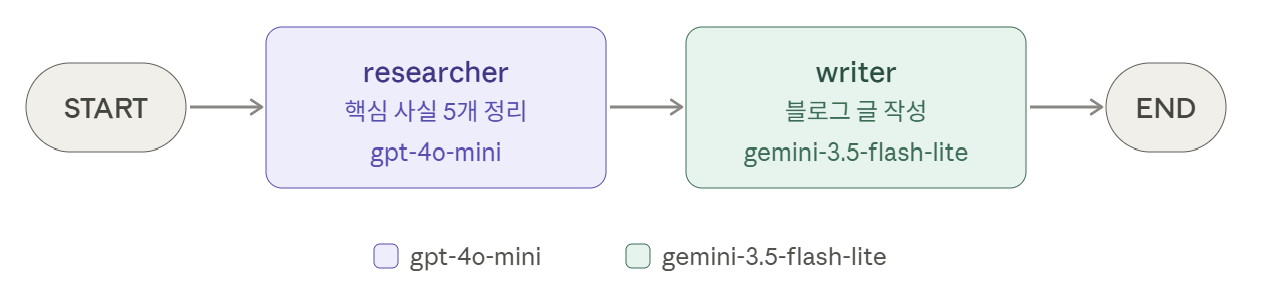

### 배울 점
| 개념 | 설명 |
|---|---|
| **공유 State** | 에이전트끼리 직접 대화하지 않습니다. 하나의 State(공용 칠판)에 결과를 쓰고, 다음 에이전트가 그것을 읽습니다. |
| **역할별 시스템 프롬프트** | 같은 LLM이라도 프롬프트로 역할을 좁히면 품질과 예측 가능성이 올라갑니다. |
| **노드는 바뀐 부분만 반환** | 노드는 State 전체가 아니라 **자기가 갱신할 키만** 딕셔너리로 돌려줍니다. |

In [4]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import SystemMessage, HumanMessage


# 1) 공유 State 정의: 에이전트들이 함께 쓰는 '칠판'
class PipelineState(TypedDict):
    topic: str      # 사용자가 준 주제
    research: str   # 리서처가 채움
    article: str    # 작성자가 채움


# 2-1) 리서처 노드 정의
def researcher(state: PipelineState) -> dict:
    # 리서처: 주제에 대한 핵심 사실 5개를 정리합니다
    msgs = [
        SystemMessage("너는 꼼꼼한 리서처다. 주제에 대한 핵심 사실 5개를 한국어 bullet 로만 정리해라. 추측은 쓰지 마라."),
        HumanMessage(f"주제: {state['topic']}"),
    ]
    result = gpt.invoke(msgs)
    print("🔎 [researcher] 자료 조사 완료")
    return {"research": result.text}          # 바뀐 키만 반환

# 2-2) 작성자 노드 정의
def writer(state: PipelineState) -> dict:
    # 작성자: 리서처의 자료만 근거로 짧은 블로그 글을 씁니다
    msgs = [
        SystemMessage("너는 친근한 IT 블로거다. 주어진 자료만 근거로 300자 내외의 한국어 블로그 글을 써라. 제목을 첫 줄에 넣어라."),
        HumanMessage(f"자료:\n{state['research']}"),
    ]
    result = gemini.invoke(msgs)
    print("✍️ [writer] 글 작성 완료")
    return {"article": result.text}


# 3) 그래프 조립
builder = StateGraph(PipelineState)
builder.add_node("researcher", researcher)
builder.add_node("writer", writer)

builder.add_edge(START, "researcher")
builder.add_edge("researcher", "writer")
builder.add_edge("writer", END)

pipeline_app = builder.compile()

In [5]:
result = pipeline_app.invoke({"topic": "멀티 에이전트 시스템이 필요한 이유"})

print("\n===== 리서처 결과 =====")
print(result["research"])
print("\n===== 작성자 결과 =====")
print(result["article"])

🔎 [researcher] 자료 조사 완료
✍️ [writer] 글 작성 완료

===== 리서처 결과 =====
- 멀티 에이전트 시스템은 복잡한 문제를 해결하기 위해 여러 개의 독립적인 에이전트가 협력하여 작업을 수행할 수 있도록 설계되었다.
- 이러한 시스템은 분산 처리 능력을 통해 성능을 향상시키고, 대규모 데이터 처리 및 실시간 반응이 필요한 상황에서 유용하다.
- 멀티 에이전트 시스템은 다양한 에이전트 간의 상호작용을 통해 자율성과 적응성을 높이며, 변화하는 환경에 효과적으로 대응할 수 있다.
- 협업을 통해 에이전트들은 서로의 강점을 활용하고, 단일 에이전트로는 해결하기 어려운 문제를 공동으로 해결할 수 있다.
- 멀티 에이전트 시스템은 로봇 공학, 자율 주행 차량, 스마트 그리드 등 다양한 분야에서 응용되고 있으며, 복잡한 시스템의 효율성을 높이는 데 기여하고 있다.

===== 작성자 결과 =====
[IT 블로그] 복잡한 문제를 해결하는 마법! 멀티 에이전트 시스템 완벽 정리

안녕하세요, 여러분! 오늘은 여러 독립적인 에이전트가 협력해 복잡한 문제를 해결하는 '멀티 에이전트 시스템'을 소개해 드릴게요. 

이 시스템은 분산 처리 능력으로 성능을 높이고, 대규모 데이터 처리와 실시간 반응에 아주 유용하답니다. 특히 에이전트 간의 상호작용으로 자율성과 적응성이 높아져 변화하는 환경에 효과적으로 대응할 수 있죠. 단일 에이전트로는 버거운 일도 서로의 강점을 살려 공동으로 해결해 낸다는 점이 정말 매력적이에요!

현재 로봇 공학, 자율 주행 차량, 스마트 그리드 등 다양한 분야에서 쓰이며 효율성을 쑥쑥 높여주고 있답니다. 앞으로의 활약도 기대해 주세요!


#### 정리
- 작성자는 사용자의 원래 질문을 보지 않고 **리서처가 남긴 `research`만** 읽었습니다. 각 노드가 무엇을 보게 할지 정하는 것, 즉 **컨텍스트 설계**가 멀티 에이전트 설계의 출발점입니다.
- 단순 순차 구조라면 그래프 없이 함수 두 개를 차례로 호출해도 됩니다. 그래프의 가치는 다음 예제부터 나오는 **분기, 루프, 병렬, 중단·재개**에서 드러납니다.

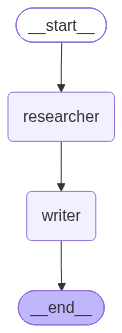

In [6]:
# 노드 워크플로우 이미지 출력
show_graph(pipeline_app)

---
### [기초] 예제 ② 질문 라우터 : 전문가에게 나눠 보내기

#### 시나리오
**라우터 에이전트**가 질문의 종류를 판단해 알맞은 전문가에게 보냅니다.

| 분류 | 담당 에이전트 | 모델 |
|---|---|---|
| `code` | 코딩 전문가 | gpt-4o-mini |
| `writing` | 글쓰기 전문가 | gemini-3.5-flash-lite |
| `general` | 일반 상담가 | gemini-3.5-flash-lite |

#### 배울 점
| 개념 | 설명 |
|---|---|
| **구조화 출력** | `with_structured_output(Pydantic 모델)`로 LLM 답을 **정해진 값 중 하나**로 강제합니다.<br> 라우팅 판단이 자유 문장이면 코드에서 분기할 수 없기 때문입니다. |
| **조건부 엣지** | `add_conditional_edges(노드, 함수)` — 함수가 반환한 노드 이름으로 다음 경로가 정해집니다. |
| **판단 근거 남기기** | `reason` 필드로 왜 그렇게 분류했는지 함께 받으면 디버깅이 쉬워집니다. |

In [7]:
from typing import Literal
from pydantic import BaseModel, Field


# 1) 라우터가 반드시 따라야 할 출력 형식
class Route(BaseModel):
    category: Literal["code", "writing", "general"] = Field(description="질문 분류")
    reason: str = Field(description="그렇게 분류한 이유 한 문장")

router_llm = gpt.with_structured_output(Route)

class RouterState(TypedDict):
    question: str
    category: str
    reason: str
    answer: str
    answered_by: str


# 2) 라우터 노드: 분류만 하고 답은 하지 않습니다
def router(state: RouterState) -> dict:
    route = router_llm.invoke([
        SystemMessage("사용자 질문을 code(프로그래밍), writing(글쓰기·문장 다듬기), general(그 외) 중 하나로 분류해라."),
        HumanMessage(state["question"]),
    ])
    print(f"🧭 [router] → {route.category}  ({route.reason})")
    return {"category": route.category, "reason": route.reason}


# 3) 전문가 에이전트를 만들어 주는 함수 (역할만 다르고 구조는 같으므로 팩토리로 만듭니다)
def make_expert(name: str, model, system_prompt: str):
    def expert(state: RouterState) -> dict:
        result = model.invoke([SystemMessage(system_prompt), HumanMessage(state["question"])])
        return {"answer": result.text, "answered_by": name}
    return expert

code_expert = make_expert("code_expert", gpt, "너는 파이썬 시니어 개발자다. 짧은 예제 코드와 함께 한국어로 답해라.")
writing_expert = make_expert("writing_expert", gemini, "너는 한국어 글쓰기 코치다. 고친 문장과 고친 이유를 함께 알려줘라.")
general_expert = make_expert("general_expert", gemini, "너는 친절한 상담가다. 세 문장 이내로 답해라.")

# 4) 조건부 엣지 함수: State를 보고 '다음 노드 이름'을 반환
def route_to_expert(state: RouterState) -> str:
    return {"code": "code_expert", "writing": "writing_expert"}.get(state["category"], "general_expert")

builder = StateGraph(RouterState)
builder.add_node("router", router)
builder.add_node("code_expert", code_expert)
builder.add_node("writing_expert", writing_expert)
builder.add_node("general_expert", general_expert)

builder.add_edge(START, "router")
builder.add_conditional_edges(
    "router",
    route_to_expert,
    ["code_expert", "writing_expert", "general_expert"],  # 갈 수 있는 경로를 명시하면 그래프 그림에 화살표가 그려집니다
)
for node in ["code_expert", "writing_expert", "general_expert"]:
    builder.add_edge(node, END)

router_app = builder.compile()

In [8]:
questions = [
    "파이썬에서 리스트 중복을 순서 유지하며 제거하려면?",
    "'회의가 진행되어지겠습니다'를 자연스럽게 고쳐줘",
    "오늘 저녁 메뉴 추천해줘",
]

for q in questions:
    print(f"\n❓ {q}")
    out = router_app.invoke({"question": q})
    print(f"💬 [{out['answered_by']}]\n{out['answer'][:300]}")


❓ 파이썬에서 리스트 중복을 순서 유지하며 제거하려면?
🧭 [router] → code  (사용자가 파이썬 코드에 대한 질문을 하고 있으며, 리스트 중복 제거와 관련된 프로그래밍 문제를 다루고 있기 때문입니다.)
💬 [code_expert]
파이썬에서 리스트의 중복 요소를 순서를 유지하며 제거하려면 `dict.fromkeys()` 메서드를 사용할 수 있습니다. 이 방법은 리스트의 순서를 유지하면서 중복을 제거합니다. 아래는 간단한 예제 코드입니다.

```python
# 중복된 요소가 있는 리스트
original_list = [1, 2, 2, 3, 4, 4, 5]

# 중복 제거
unique_list = list(dict.fromkeys(original_list))

print(unique_list)  # 출력: [1, 2, 3, 4, 5]
```

이 코드에서 `di

❓ '회의가 진행되어지겠습니다'를 자연스럽게 고쳐줘
🧭 [router] → writing  (문장을 더 자연스럽고 간결하게 다듬기 위해 수정함.)
💬 [writing_expert]
안녕하세요! 한국어 글쓰기 코치입니다. 요청하신 문장을 더 자연스럽고 올바른 표현으로 고쳐드리겠습니다.

---

### **고친 문장**
> **"회의를 시작하겠습니다."** 
> 또는
> **"회의를 진행하겠습니다."**

---

### **고친 이유**

1. **이중 피동 표현 제거 ('-되어지다')**
   * 원문인 '진행**되어지**겠습니다'는 '진행하다'에 피동 접사 '-되-'와 '-어지다'가 겹쳐서 쓰인 **이중 피동** 표현입니다. 우리말에서 이중 피동은 불필요하게 문장을 길게 만들고 어색한 느낌을 줍니다. 
 

❓ 오늘 저녁 메뉴 추천해줘
🧭 [router] → general  (저녁 메뉴 추천은 일반적인 질문으로, 프로그래밍이나 글쓰기와 관련이 없음.)
💬 [general_expert]
오늘 저녁에는 따뜻하고 감칠맛 나는 김치찌개 어떠신가요? 
만약 요리하기 귀찮으시다면 매콤달콤한 떡볶이나

**📝 정리** — 라우터가 code / writing / general로 나누고 `reason`에 이유를 남겼다. 분류처럼 틀리면 안 되는 값은 `Literal` 구조화 출력으로 범위를 막는다.

#### 정리
- 라우터는 **판단만**, 전문가는 **답변만** 합니다. 역할이 작을수록 프롬프트가 짧아지고 결과가 안정적입니다.
- 분류처럼 틀리면 안 되는 일은 `temperature=0`인 모델에 구조화 출력을 붙이는 것이 정석입니다.
- 전문가를 추가하려면 노드 하나와 `route_to_expert`의 매핑 한 줄만 늘리면 됩니다.

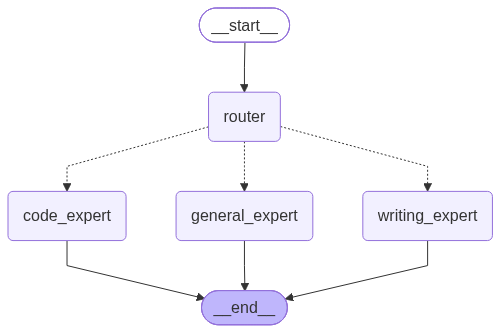

In [9]:
show_graph(router_app)

---
### [중급] 예제 ③ 감독자(Supervisor)와 도구 사용 에이전트

#### 시나리오
"서울 출장 3일 동안 하루 식비 45,000원이면 총 얼마고, 서울 날씨는 어때?" 처럼 **여러 전문 영역이 섞인 요청**을 감독자가 쪼개서 하위 에이전트에게 차례로 맡깁니다.

| 에이전트 | 모델 | 도구 |
|---|---|---|
| **supervisor** (감독자) | gpt-4o-mini | 없음 — 누구에게 무슨 일을 시킬지만 결정 |
| **calc_agent** (계산원) | gpt-4o-mini | `add`, `multiply` |
| **travel_agent** (여행 도우미) | gemini-3.5-flash-lite | `get_weather` |

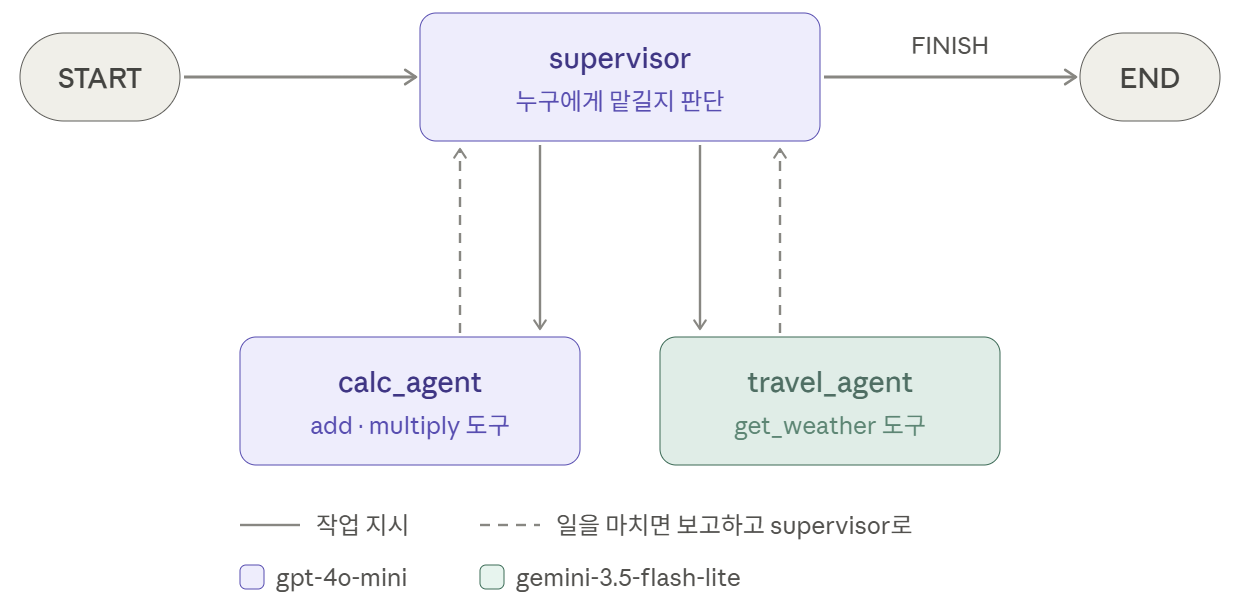

#### 배울 점
| 개념 | 설명 |
|---|---|
| **`create_agent`** | LangChain 1.x의 에이전트 생성 함수. 모델 + 도구 → "생각 → 도구 호출 → 결과 확인" 루프(ReAct)를 가진 그래프를 만들어 줍니다. |
| **에이전트를 노드로** | `create_agent`가 만든 것도 그래프이므로, 그대로 부모 그래프의 노드 안에서 호출할 수 있습니다. |
| **`Command` 핸드오프** | 노드가 `Command(goto=다음노드, update=State변경)`를 반환하면 엣지를 미리 그리지 않아도 이동할 곳을 스스로 정합니다. |
| **컨텍스트 격리** | 하위 에이전트에게는 전체 대화가 아니라 감독자가 정리한 **작업 지시서 한 줄**만 줍니다. 토큰을 아끼고 혼선을 막습니다. |
| **루프 상한** | 감독자 패턴은 무한 반복될 수 있으므로 `steps`로 최대 횟수를 둡니다. |

In [10]:
from typing import Annotated
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, AnyMessage
from langgraph.graph.message import add_messages
from langgraph.types import Command


# 1) 도구 정의 — docstring이 곧 LLM에게 주는 도구 설명서입니다
@tool
def add(a: float, b: float) -> float:
    "두 수를 더한다."
    return a + b

@tool
def multiply(a: float, b: float) -> float:
    "두 수를 곱한다."
    return a * b

@tool
def get_weather(city: str) -> str:
    "도시 이름을 받아 현재 날씨를 알려준다."
    fake_db = {"서울": "맑음, 18°C", "부산": "흐림, 21°C", "제주": "비, 19°C"}  # 수업용 가짜 데이터
    return fake_db.get(city, "날씨 정보 없음")

# 2) 하위 에이전트 생성 (각자 자기 도구만 가집니다)
calc_agent = create_agent(
    model=gpt,
    tools=[add, multiply],
    system_prompt="너는 계산원이다. 반드시 도구로 계산하고, 결과를 한 문장으로 보고해라.",
    name="calc_agent",
)

travel_agent = create_agent(
    model=gemini,
    tools=[get_weather],
    system_prompt="너는 여행 도우미다. 날씨는 반드시 get_weather 도구로 확인하고, 옷차림 조언을 한 문장 덧붙여라.",
    name="travel_agent",
)

In [11]:
MAX_STEPS = 6   # 감독자 루프 상한


class SupervisorState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]  # 대화 기록 (리듀서: 이어 붙이기)
    task: str      # 감독자가 하위 에이전트에게 주는 작업 지시
    steps: int     # 지금까지 감독자가 판단한 횟수


class Decision(BaseModel):
    next: Literal["calc_agent", "travel_agent", "FINISH"] = Field(description="다음에 일할 에이전트, 모두 끝났으면 FINISH")
    task: str = Field(description="선택한 에이전트에게 줄 구체적인 작업 지시. FINISH면 사용자에게 줄 최종 답변")


supervisor_llm = gpt.with_structured_output(Decision)

SUPERVISOR_PROMPT = (
    "너는 팀장이다. 팀원: calc_agent(계산), travel_agent(날씨·여행).\n"
    "대화 기록을 보고 아직 처리되지 않은 일을 한 번에 하나씩 팀원에게 맡겨라.\n"
    "모든 일이 끝났으면 next=FINISH 로 하고, task 에 팀원들의 결과를 종합한 최종 답변을 써라."
)


# 3) 감독자 노드 — Command 로 다음 목적지를 직접 지정합니다
def supervisor(state: SupervisorState) -> Command[Literal["calc_agent", "travel_agent", "__end__"]]:  # END 도 사용 가능
    steps = state.get("steps", 0) + 1

    if steps > MAX_STEPS:   # 안전장치: 너무 오래 돌면 강제 종료
        return Command(goto=END, update={"messages": [AIMessage("작업 단계가 너무 많아 중단했습니다.", name="supervisor")]})

    d = supervisor_llm.invoke([SystemMessage(SUPERVISOR_PROMPT)] + state["messages"])
    print(f"👔 [supervisor #{steps}] → {d.next}: {d.task}")

    if d.next == "FINISH":
        return Command(goto=END, update={"messages": [AIMessage(d.task, name="supervisor")], "steps": steps})
    return Command(goto=d.next, update={"task": d.task, "steps": steps})


# 4) 하위 에이전트를 감싸는 노드 — 작업 지시만 전달하고, 최종 보고만 대화에 남깁니다
def make_worker(name: str, agent):
    def worker(state: SupervisorState) -> Command[Literal["supervisor"]]:
        result = agent.invoke({"messages": [HumanMessage(state["task"])]})   # 컨텍스트 격리
        report = result["messages"][-1].text
        print(f"   🛠️ [{name}] {report}")
        return Command(
            goto="supervisor",
            update={"messages": [AIMessage(report, name=name)]},
        )
    return worker


builder = StateGraph(SupervisorState)
builder.add_node("supervisor", supervisor)
builder.add_node("calc_agent", make_worker("calc_agent", calc_agent))
builder.add_node("travel_agent", make_worker("travel_agent", travel_agent))

builder.add_edge(START, "supervisor")   # 나머지 이동은 모두 Command 가 결정합니다
supervisor_app = builder.compile()

In [12]:
request = "서울 출장 3일 동안 하루 식비가 45,000원이면 총 식비는 얼마야? 그리고 서울 날씨도 알려줘."

out = supervisor_app.invoke({"messages": [HumanMessage(request)], "steps": 0})

print("\n===== 최종 답변 =====")
print(out["messages"][-1].text)

👔 [supervisor #1] → calc_agent: 서울 출장 3일 동안 하루 식비가 45,000원이면 총 식비는 135,000원입니다.
   🛠️ [calc_agent] 총 식비는 135,000원입니다.
👔 [supervisor #2] → travel_agent: 서울의 날씨를 알려줘.
   🛠️ [travel_agent] 현재 서울은 맑고 기온은 18°C입니다. 

일교차가 클 수 있으니 가벼운 겉옷을 챙기시는 것이 좋겠습니다.
👔 [supervisor #3] → FINISH: 서울 출장 3일 동안 하루 식비가 45,000원이면 총 식비는 135,000원입니다. 현재 서울은 맑고 기온은 18°C입니다. 일교차가 클 수 있으니 가벼운 겉옷을 챙기시는 것이 좋겠습니다.

===== 최종 답변 =====
서울 출장 3일 동안 하루 식비가 45,000원이면 총 식비는 135,000원입니다. 현재 서울은 맑고 기온은 18°C입니다. 일교차가 클 수 있으니 가벼운 겉옷을 챙기시는 것이 좋겠습니다.


**📝 정리** — 감독자가 calc_agent에게 일을 넘기면서 작업 지시에 **"총 식비는 135,000원입니다"라고 이미 계산해서** 보냈다. 계산 도구가 있는 하위 에이전트를 두고도 감독자 LLM이 직접 계산한 것(이번엔 맞았지만 검증되지 않은 값).

#### 정리
- 이 예제의 그래프에는 감독자에서 나가는 엣지를 하나도 그리지 않았습니다. 대신 함수의 반환 타입 `Command[Literal[...]]`에 갈 수 있는 곳을 적어 두면 LangGraph가 그것을 읽어 **그래프 그림에도 화살표를 그려 줍니다**.
- 하위 에이전트의 도구 호출 과정(ToolMessage 등)은 부모 대화에 남기지 않고 **최종 보고만** 남겼습니다. 에이전트 수가 늘어날수록 이 차이가 토큰 비용과 정확도에 크게 영향을 줍니다.
- 실무에서는 `MAX_STEPS` 같은 상한이 없으면 감독자가 같은 일을 반복 지시하는 루프에 빠질 수 있습니다.

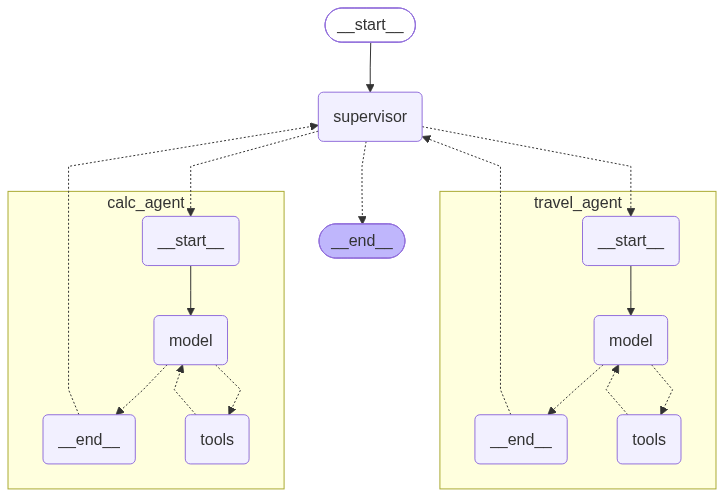

In [13]:
# xray=True 이므로 calc_agent / travel_agent 내부의 ReAct 구조까지 함께 보입니다
show_graph(supervisor_app)

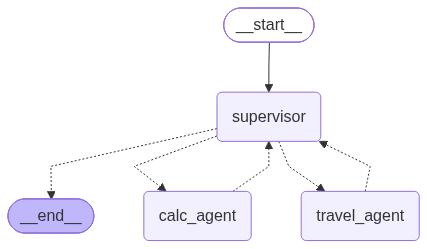

In [14]:
display(supervisor_app)

> 하위 에이전트 하나만 따로 그려 보면 `create_agent`가 만든 **model ↔ tools 루프**를 확인할 수 있습니다.

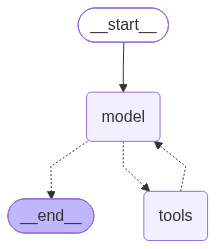

In [15]:
show_graph(calc_agent)

---
### [중급] 예제 ④ 다관점 병렬 리뷰 : Map-Reduce

#### 시나리오
사용자의 아이디어를 **기획자 에이전트**가 검토 관점 3~4개로 나누고, 관점마다 **리뷰어 에이전트를 동시에** 실행한 뒤, **종합 에이전트**가 결과를 하나로 묶습니다. 리뷰어는 짝수/홀수 순서에 따라 gpt와 gemini를 번갈아 사용해 시각을 다양화합니다.

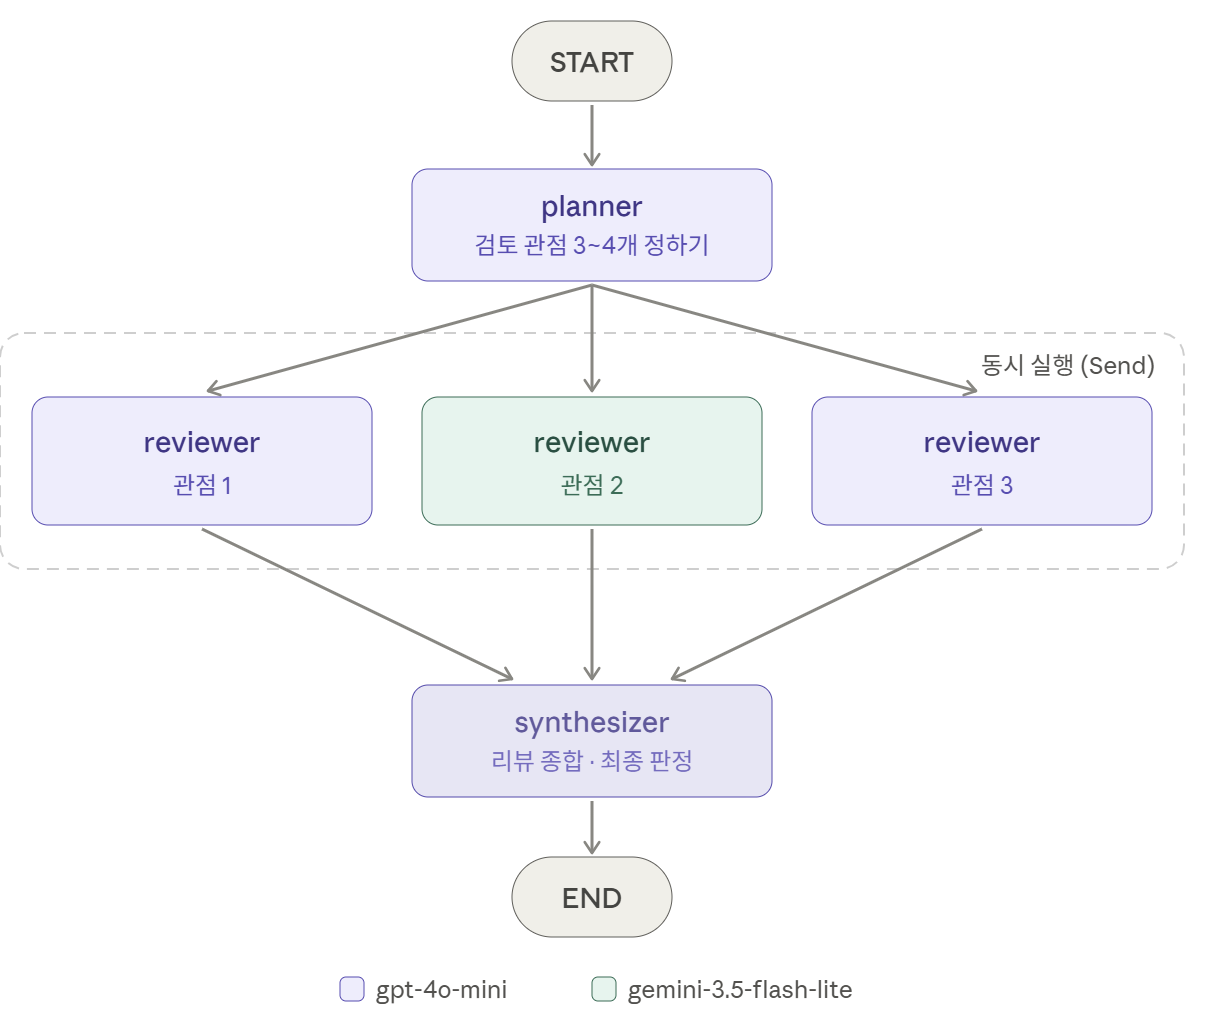

#### 배울 점
| 개념 | 설명 |
|---|---|
| **`Send(노드, 입력)`** | 실행 시점에 개수가 정해지는 작업을 동적으로 병렬 실행합니다. 관점이 3개면 3개, 5개면 5개가 동시에 돕니다. |
| **리듀서 `operator.add`** | 여러 노드가 **같은 키에 동시에** 값을 쓰면 충돌합니다. `Annotated[list, operator.add]`로 선언하면 각자의 결과가 리스트에 **이어 붙여집니다**. |
| **노드별 입력 스키마** | `Send`로 보내는 딕셔너리는 전체 State와 달라도 됩니다. 리뷰어는 자기 관점 하나만 받습니다. |
| **팬인(Fan-in)** | 모든 리뷰어가 끝나야 synthesizer가 한 번 실행됩니다. LangGraph가 대기와 합류를 알아서 처리합니다. |

In [16]:
import operator
from langgraph.types import Send

class ReviewState(TypedDict):
    idea: str
    perspectives: list[str]
    reviews: Annotated[list[str], operator.add]   # ⭐ 병렬 결과를 이어 붙이는 리듀서
    final_report: str

class ReviewerInput(TypedDict):     # 리뷰어 한 명이 받는 입력 (Send 로 전달)
    idea: str
    perspective: str
    index: int

class Plan(BaseModel):
    perspectives: list[str] = Field(description="아이디어를 검토할 서로 다른 관점 3~4개 (예: 시장성, 기술 난이도)")

# 1) 기획자: 검토 관점을 정합니다
def planner(state: ReviewState) -> dict:
    plan = gpt.with_structured_output(Plan).invoke(
        f"다음 아이디어를 평가할 관점 3~4개를 정해라.\n아이디어: {state['idea']}"
    )
    print(f"🗂️ [planner] 관점: {plan.perspectives}")
    return {"perspectives": plan.perspectives}


# 2) 조건부 엣지에서 Send 리스트를 반환 → 관점 수만큼 reviewer 가 병렬 실행됩니다
def dispatch(state: ReviewState) -> list[Send]:
    return [
        Send("reviewer", {"idea": state["idea"], "perspective": p, "index": i})
        for i, p in enumerate(state["perspectives"])
    ]


# 3) 리뷰어: 한 가지 관점으로만 평가 (모델을 번갈아 사용)
def reviewer(inp: ReviewerInput) -> dict:
    model, model_name = (gpt, "gpt") if inp["index"] % 2 == 0 else (gemini, "gemini")
    result = model.invoke([
        SystemMessage(f"너는 '{inp['perspective']}' 관점의 전문 심사위원이다. 장점 1개, 우려 1개, 점수(10점 만점)를 세 줄로 답해라."),
        HumanMessage(inp["idea"]),
    ])
    print(f"   🧑‍⚖️ [reviewer:{model_name}] {inp['perspective']} 완료")
    return {"reviews": [f"### {inp['perspective']} ({model_name})\n{result.text}"]}   # 리스트로 반환!


# 4) 종합: 모든 리뷰를 하나의 보고서로
def synthesizer(state: ReviewState) -> dict:
    joined = "\n\n".join(state["reviews"])
    result = gpt.invoke([
        SystemMessage("심사 결과들을 종합해 '최종 판정(진행/보완 후 진행/보류)'과 핵심 근거 3줄을 한국어로 써라."),
        HumanMessage(joined),
    ])
    return {"final_report": result.text}


builder = StateGraph(ReviewState)
builder.add_node("planner", planner)
builder.add_node("reviewer", reviewer)
builder.add_node("synthesizer", synthesizer)

builder.add_edge(START, "planner")
builder.add_conditional_edges("planner", dispatch, ["reviewer"])
builder.add_edge("reviewer", "synthesizer")   # 모든 reviewer 가 끝난 뒤 한 번만 실행
builder.add_edge("synthesizer", END)

review_app = builder.compile()

In [17]:
import time

idea = "동네 소상공인을 위한, 사진만 찍으면 메뉴판과 SNS 홍보글을 자동으로 만들어 주는 AI 앱"

start = time.perf_counter()
out = review_app.invoke({"idea": idea})
print(f"\n⏱️ 소요 시간: {time.perf_counter() - start:.1f}초 (리뷰어들이 동시에 실행됨)")

print(f"\n===== 개별 리뷰 {len(out['reviews'])}건 =====")
for r in out["reviews"]:
    print(r, "\n")

print("===== 최종 판정 =====")
print(out["final_report"])

🗂️ [planner] 관점: ['기술적 실현 가능성: AI 기술이 사진 인식 및 자연어 처리를 통해 메뉴판과 SNS 홍보글을 자동으로 생성할 수 있는지 평가.', '시장 수요: 동네 소상공인들이 이러한 서비스를 필요로 하는지, 그리고 경쟁 서비스와의 차별점은 무엇인지 분석.', '사용자 경험: 앱의 사용 편의성, 직관성, 그리고 소상공인들이 쉽게 접근하고 활용할 수 있는지에 대한 평가.', '비즈니스 모델: 이 앱의 수익 모델은 무엇인지, 소상공인들에게 적정 가격으로 제공할 수 있는지 검토.']
   🧑‍⚖️ [reviewer:gemini] 시장 수요: 동네 소상공인들이 이러한 서비스를 필요로 하는지, 그리고 경쟁 서비스와의 차별점은 무엇인지 분석. 완료
   🧑‍⚖️ [reviewer:gemini] 비즈니스 모델: 이 앱의 수익 모델은 무엇인지, 소상공인들에게 적정 가격으로 제공할 수 있는지 검토. 완료
   🧑‍⚖️ [reviewer:gpt] 기술적 실현 가능성: AI 기술이 사진 인식 및 자연어 처리를 통해 메뉴판과 SNS 홍보글을 자동으로 생성할 수 있는지 평가. 완료
   🧑‍⚖️ [reviewer:gpt] 사용자 경험: 앱의 사용 편의성, 직관성, 그리고 소상공인들이 쉽게 접근하고 활용할 수 있는지에 대한 평가. 완료

⏱️ 소요 시간: 6.0초 (리뷰어들이 동시에 실행됨)

===== 개별 리뷰 4건 =====
### 기술적 실현 가능성: AI 기술이 사진 인식 및 자연어 처리를 통해 메뉴판과 SNS 홍보글을 자동으로 생성할 수 있는지 평가. (gpt)
장점: AI 기술을 활용하여 소상공인이 손쉽게 메뉴판과 SNS 홍보글을 생성할 수 있어 시간과 비용을 절감할 수 있습니다.  
우려: 사진 인식 및 자연어 처리의 정확성이 낮을 경우, 생성된 콘텐츠의 품질이 떨어져 브랜드 이미지에 부정적인 영향을 미칠 수 있습니다.  
점수: 8/10. 

### 시장 수요: 동네 소상공인들이 이러한 서비스를 필요로 하는지, 그리고 경쟁 서비스와의 차별점은 무엇인

**📝 정리** — 리뷰어 4개가 동시에 실행되어 6.0초. 완료 순서(gemini, gemini, gpt, gpt)가 요청 순서와 다르다. 순서가 필요하면 `index`로 다시 정렬한다.

#### 정리
- `reviews`에서 `operator.add`를 빼고 실행해 보세요. 여러 노드가 같은 단계에서 한 키를 동시에 갱신하므로 `InvalidUpdateError`가 납니다. **병렬 = 리듀서 필수**라고 기억하면 됩니다.
- 병렬 결과의 **순서는 보장되지 않습니다**. 순서가 중요하면 `index`를 결과에 함께 담아 집계 단계에서 정렬하세요.
- 고정 개수 병렬이라면 엣지를 여러 개 그리면 되지만, 개수가 실행 중에 정해진다면 `Send`가 정답입니다.

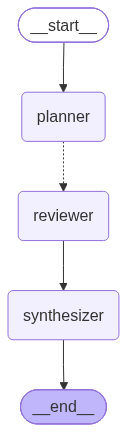

In [18]:
show_graph(review_app)

- Send: 특정 노드에 별도의 입력을 전달해 실행합니다. 여러 입력으로 같은 노드를 여러 번 실행하는 병렬 처리에 특히 유용합니다.
- Command: 현재 노드의 실행 결과로 State를 업데이트하고, 다음에 실행할 노드를 지정합니다.

---
### [고급] 예제 ⑤ 작성자·비평가 자기 개선 루프 + 사람 승인 (HITL)

#### 시나리오
제품 소개 문구를 만드는 팀입니다.
1. **writer** (`gemini`)가 초안을 쓰고
2. **critic** (`gpt`)이 점수와 피드백을 줍니다. 기준 점수 미달이면 writer가 피드백을 반영해 **다시 씁니다**.
3. 통과하거나 수정 한도에 닿으면 **사람이 최종 확인**합니다 (`interrupt`로 그래프가 멈춤).
4. 사람이 승인하면 끝, 수정을 요청하면 그 의견을 반영해 다시 writer로 돌아갑니다.

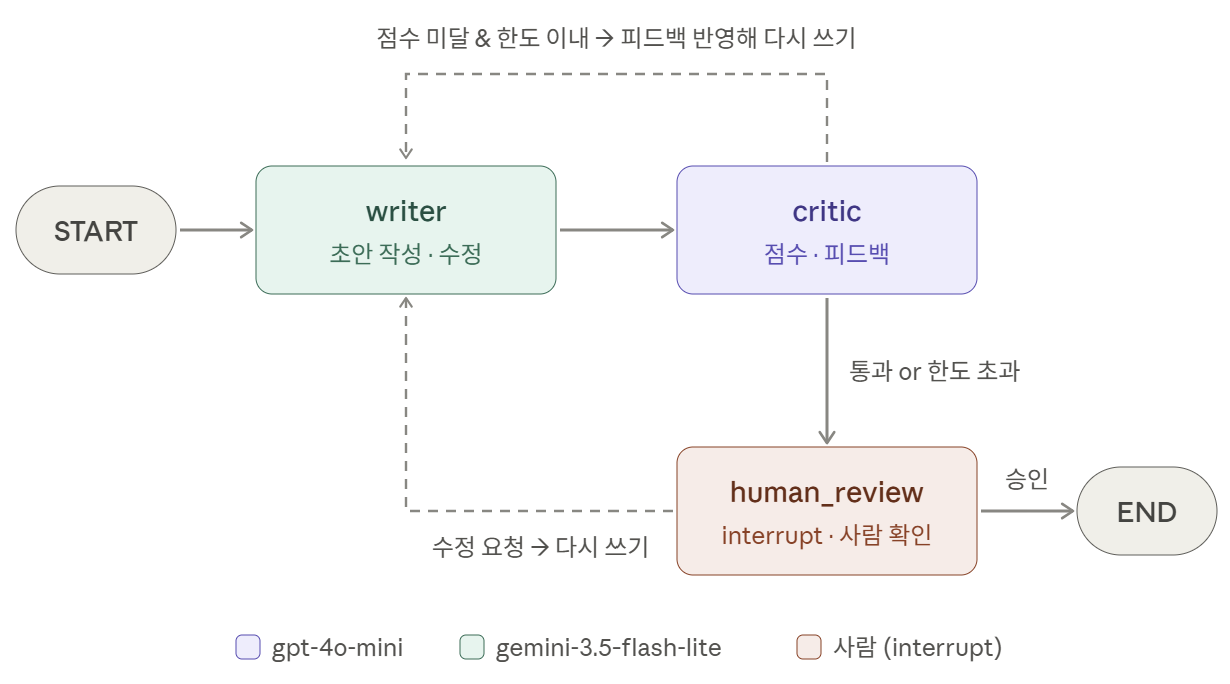

#### 배울 점
| 개념 | 설명 |
|---|---|
| **자기 개선 루프** | 생성 에이전트와 평가 에이전트를 분리하면 스스로 품질을 끌어올리는 구조가 됩니다. 서로 다른 모델을 쓰면 "자기 글에 관대한" 문제도 줄어듭니다. |
| **체크포인터 (`InMemorySaver`)** | 단계마다 State를 저장합니다. `interrupt`로 멈췄다 다시 이어가려면 **반드시** 필요합니다. |
| **`thread_id`** | 저장된 State를 구분하는 대화 ID입니다. 재개할 때 **같은 `thread_id`** 를 써야 멈춘 지점부터 이어집니다. |
| **`interrupt()` / `Command(resume=...)`** | 노드 안에서 `interrupt(질문)`을 호출하면 그래프가 멈추고, `Command(resume=답)`으로 재개하면 `interrupt()`가 그 답을 반환합니다. |
| **`RetryPolicy`** | LLM API의 일시적 오류(타임아웃, 429 등)에 노드 단위로 자동 재시도합니다. |
| **스트리밍 (`stream_mode="updates"`)** | 노드가 끝날 때마다 진행 상황을 받아 볼 수 있어, 오래 걸리는 멀티 에이전트 작업의 진행 표시에 씁니다. |

In [19]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, RetryPolicy

PASS_SCORE = 8      # 비평가 통과 기준 점수
MAX_REVISIONS = 3   # 자동 수정 최대 횟수

class CopyState(TypedDict):
    product: str
    draft: str
    feedback: str
    score: int
    revisions: int
    approved: bool

class Critique(BaseModel):
    score: int = Field(ge=1, le=10, description="10점 만점 점수")
    feedback: str = Field(description="구체적인 개선점 1~2개. 통과 수준이면 '없음'")

# 1) 작성자: 피드백이 있으면 반영해서 고쳐 씁니다
def writer(state: CopyState) -> dict:
    if state.get("feedback"):
        prompt = f"이전 문구:\n{state['draft']}\n\n피드백:\n{state['feedback']}\n\n피드백을 반영해 문구를 다시 써라."
    else:
        prompt = f"제품: {state['product']}\n이 제품의 소개 문구를 3문장 이내로 써라."
    result = gemini.invoke([SystemMessage("너는 카피라이터다. 과장 없이, 구체적인 혜택이 드러나게 써라."), HumanMessage(prompt)])
    return {"draft": result.text, "revisions": state.get("revisions", 0) + 1}

# 2) 비평가: 점수와 피드백
def critic(state: CopyState) -> dict:
    c = gpt.with_structured_output(Critique).invoke([
        SystemMessage("너는 깐깐한 마케팅 팀장이다. 명확성, 구체적 혜택, 간결성을 기준으로 엄격하게 채점해라."),
        HumanMessage(f"제품: {state['product']}\n문구:\n{state['draft']}"),
    ])
    return {"score": c.score, "feedback": c.feedback}

# 3) 비평 결과에 따른 분기
def after_critic(state: CopyState) -> str:
    if state["score"] >= PASS_SCORE or state["revisions"] >= MAX_REVISIONS:
        return "human_review"
    return "writer"

# 4) 사람 검토: 여기서 그래프가 멈춥니다
def human_review(state: CopyState) -> Command[Literal["writer", "__end__"]]:
    answer = interrupt({                        # ⏸️ 이 값이 호출자에게 전달되고 실행이 중단됨
        "질문": "이 문구를 승인할까요? 승인하려면 'ok', 아니면 수정 의견을 입력하세요.",
        "문구": state["draft"],
        "AI 점수": state["score"],
    })
    # ▶️ Command(resume=...) 로 재개되면 answer 에 사람의 답이 들어옵니다
    if answer.strip().lower() == "ok":
        return Command(goto=END, update={"approved": True})
    return Command(goto="writer", update={"feedback": f"[사람 의견] {answer}", "revisions": 0})

retry = RetryPolicy(max_attempts=3, initial_interval=1.0)   # LLM 호출 노드에만 재시도 적용

builder = StateGraph(CopyState)
builder.add_node("writer", writer, retry_policy=retry)
builder.add_node("critic", critic, retry_policy=retry)
builder.add_node("human_review", human_review)

builder.add_edge(START, "writer")
builder.add_edge("writer", "critic")
builder.add_conditional_edges("critic", after_critic, ["writer", "human_review"])

copy_app = builder.compile(checkpointer=InMemorySaver())   # ⭐ interrupt 를 쓰려면 체크포인터 필수

#### 실행 헬퍼
`stream_mode="updates"`로 노드가 끝날 때마다 진행 상황을 출력하고, 그래프가 `interrupt`로 멈추면 그 질문을 보여 줍니다.

In [20]:
def run_and_watch(payload, config):
    # 그래프를 스트리밍 실행하고, 멈추면 interrupt 내용을 반환합니다
    for chunk in copy_app.stream(payload, config, stream_mode="updates"):
        for node, update in chunk.items():
            if node == "__interrupt__":
                info = update[0].value
                print("\n⏸️  사람 검토 대기 중")
                print(f"   AI 점수: {info['AI 점수']}")
                print(f"   문구: {info['문구']}")
                return info
            if node == "writer":
                print(f"✍️ [writer] {update['revisions']}번째 초안 작성")
            elif node == "critic":
                print(f"🧐 [critic] 점수 {update['score']} / 피드백: {update['feedback']}")
            elif node == "human_review":
                print("🙋 [human_review] 처리 완료")
    return None


config = {"configurable": {"thread_id": "copy-001"}}   # 같은 thread_id 로 재개해야 합니다

# ① 첫 실행: 자동 루프를 돌다가 human_review 에서 멈춥니다
run_and_watch({"product": "한 번 충전으로 일주일 쓰는 초경량 무선 마우스"}, config)

✍️ [writer] 1번째 초안 작성
🧐 [critic] 점수 7 / 피드백: 문구는 제품의 주요 장점을 잘 설명하고 있지만, 더 간결하게 표현할 수 있습니다. 예를 들어, '단 1회 충전으로 최대 7일간 사용 가능'과 같은 문구로 시작하면 명확성을 높일 수 있습니다. 또한, '계란 하나보다 가벼운' 표현은 구체적이지만, 무게를 숫자로 제시하면 더 효과적일 것입니다.
✍️ [writer] 2번째 초안 작성
🧐 [critic] 점수 8 / 피드백: 문구는 명확하고 구체적인 혜택을 잘 전달하고 있습니다. 그러나 문구가 다소 길어 간결성을 개선할 필요가 있습니다.

⏸️  사람 검토 대기 중
   AI 점수: 8
   문구: 단 1회 충전으로 최대 7일간 사용 가능하여 매번 충전하는 번거로움을 없앴습니다. 
50g 초경량 설계로 장시간 사용해도 손목에 무리가 가지 않습니다. 
책상 위를 깔끔하게 만드는 무선의 자유로움과 편안한 그립감을 직접 경험해 보세요.


{'질문': "이 문구를 승인할까요? 승인하려면 'ok', 아니면 수정 의견을 입력하세요.",
 '문구': '단 1회 충전으로 최대 7일간 사용 가능하여 매번 충전하는 번거로움을 없앴습니다. \n50g 초경량 설계로 장시간 사용해도 손목에 무리가 가지 않습니다. \n책상 위를 깔끔하게 만드는 무선의 자유로움과 편안한 그립감을 직접 경험해 보세요.',
 'AI 점수': 8}

**📝 정리** — 7점 → 수정 → 8점 통과 → `human_review`의 `interrupt()`에서 멈췄다.

#### 사람의 답으로 재개하기
수업에서 끊김 없이 실행되도록 답을 변수로 넣었습니다. 직접 입력해 보려면 주석 처리된 `input()` 줄을 사용하세요.

In [21]:
# ② 첫 번째 검토: 수정 의견을 주면 writer 로 돌아가 다시 씁니다
human_answer = "대학생 타깃이 드러나게, 가격 대비 장점을 한 문장 넣어줘"
# human_answer = input("승인하려면 ok, 아니면 수정 의견: ")

run_and_watch(Command(resume=human_answer), config)

🙋 [human_review] 처리 완료
✍️ [writer] 1번째 초안 작성
🧐 [critic] 점수 7 / 피드백: 문구는 제품의 주요 혜택을 잘 전달하고 있으나, 더 간결하게 표현할 수 있습니다. 예를 들어, '5만 원대의 합리적인 가격' 대신 '5만 원대'로 줄이고, '손목에 무리가 가지 않습니다'를 '편안한 사용감'으로 간단히 표현하면 좋겠습니다.
✍️ [writer] 2번째 초안 작성
🧐 [critic] 점수 7 / 피드백: 문구는 제품의 주요 특징을 잘 설명하고 있지만, 구체적인 혜택이 부족합니다. 예를 들어, '편안한 사용감' 대신 어떤 방식으로 편안한지 구체적으로 설명하면 좋겠습니다. 또한, 문구가 다소 길어 간결성을 높일 필요가 있습니다.
✍️ [writer] 3번째 초안 작성
🧐 [critic] 점수 7 / 피드백: 문구는 제품의 주요 특징을 잘 전달하고 있으나, 구체적인 혜택이 부족합니다. 예를 들어, '손목 부담 없는 그립감' 대신 '인체공학적 디자인으로 손목 통증을 줄여줍니다'와 같은 구체적인 설명이 필요합니다. 또한, 가격 정보는 좋지만, '5만 원대'라는 표현은 다소 모호하므로 정확한 가격을 제시하는 것이 좋습니다.

⏸️  사람 검토 대기 중
   AI 점수: 7
   문구: 충전은 일주일에 한 번, 무게는 계란 한 판보다 가벼운 50g. 

5만 원대 가격으로 도서관 책상 위가 무선으로 가벼워집니다. 손목 부담 없는 그립감으로 장시간 과제에도 피로감이 적습니다.


{'질문': "이 문구를 승인할까요? 승인하려면 'ok', 아니면 수정 의견을 입력하세요.",
 '문구': '충전은 일주일에 한 번, 무게는 계란 한 판보다 가벼운 50g. \n\n5만 원대 가격으로 도서관 책상 위가 무선으로 가벼워집니다. 손목 부담 없는 그립감으로 장시간 과제에도 피로감이 적습니다.',
 'AI 점수': 7}

**📝 정리** — 사람 의견을 받고 `revisions`를 0으로 되돌려 다시 썼지만 7, 7, 7점으로 상한까지 돌았다. 비평가의 기준과 사람의 요구가 다르면 자동 루프는 횟수만 쓴다.

In [22]:
# ③ 두 번째 검토: 승인
run_and_watch(Command(resume="ok"), config)

final = copy_app.get_state(config).values
print("\n===== 최종 승인 문구 =====")
print(final["draft"])
print(f"\n승인 여부: {final['approved']}")

🙋 [human_review] 처리 완료

===== 최종 승인 문구 =====
충전은 일주일에 한 번, 무게는 계란 한 판보다 가벼운 50g. 

5만 원대 가격으로 도서관 책상 위가 무선으로 가벼워집니다. 손목 부담 없는 그립감으로 장시간 과제에도 피로감이 적습니다.

승인 여부: True


**📝 정리** — 최종 문구의 "**계란 한 판보다 가벼운 50g**"은 초안의 "계란 하나보다 가벼운"이 수정 중에 바뀐 것이다. 계란 한 판과 비교하면 의미가 없다. 점수 대신 사실 관계를 보는 검토 기준이 필요하다.

### 체크포인터가 저장한 이력 확인
`get_state_history()`로 각 단계에서 저장된 스냅숏을 거꾸로 훑어볼 수 있습니다. 장애 분석이나 특정 시점으로 되돌아가는 **타임 트래블** 기능의 기반입니다.

In [23]:
for snap in copy_app.get_state_history(config):
    v = snap.values
    print(f"다음 노드: {str(snap.next):28} | revisions={v.get('revisions')} | score={v.get('score')}")

다음 노드: ()                           | revisions=3 | score=7
다음 노드: ('human_review',)            | revisions=3 | score=7
다음 노드: ('critic',)                  | revisions=3 | score=7
다음 노드: ('writer',)                  | revisions=2 | score=7
다음 노드: ('critic',)                  | revisions=2 | score=7
다음 노드: ('writer',)                  | revisions=1 | score=7
다음 노드: ('critic',)                  | revisions=1 | score=8
다음 노드: ('writer',)                  | revisions=0 | score=8
다음 노드: ('human_review',)            | revisions=2 | score=8
다음 노드: ('critic',)                  | revisions=2 | score=7
다음 노드: ('writer',)                  | revisions=1 | score=7
다음 노드: ('critic',)                  | revisions=1 | score=None
다음 노드: ('writer',)                  | revisions=None | score=None
다음 노드: ('__start__',)               | revisions=None | score=None


**📝 정리** — 체크포인터가 스냅숏 14개를 저장했다. `next`가 `('human_review',)`인 시점이 멈춘 곳이다.

#### 정리
- **멈춘 노드는 재개될 때 처음부터 다시 실행됩니다.** 그래서 `interrupt()` 앞에는 다시 실행돼도 괜찮은 코드만 두어야 합니다 (예: 결제·메일 발송 같은 부작용은 `interrupt` 뒤로).
- 체크포인터가 없으면 `interrupt`는 동작하지 않습니다. 운영 환경에서는 `InMemorySaver` 대신 SQLite/Postgres 체크포인터를 써서 서버가 재시작돼도 이어갈 수 있게 합니다.
- 사람이 수정을 요청하면 `revisions`를 0으로 되돌려 자동 루프 기회를 다시 주었습니다. 이런 **루프 카운터 관리**가 고급 멀티 에이전트 설계의 핵심 디테일입니다.

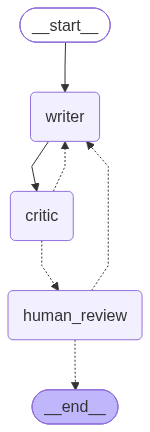

In [24]:
show_graph(copy_app)

---
### [정리] `create_agent` + 미들웨어 vs LangGraph : 언제 무엇을 쓸까?

LangChain 1.x의 미들웨어를 잘 쓰면 분기·반복·병렬·기억·사람 승인을 꽤 많이 구현할 수 있습니다. 그런데도 예제 ①②④⑤는 왜 LangGraph로 직접 그래프를 그렸을까요?

#### 핵심 : 에이전트의 "모양"
- `create_agent`도 내부는 LangGraph 그래프지만, 노드가 **`model` ⇄ `tools` 두 개로 고정**되어 있습니다.
- 미들웨어는 이 고정된 루프의 **앞·뒤·사이에 끼어드는 훅**일 뿐, 새 노드(업무 단계)를 만들지 못합니다.
- 실제로 미들웨어 훅이 `jump_to`로 이동할 수 있는 곳은 아래 셀에서 보듯 **세 곳뿐**입니다.

In [25]:
from typing import get_args
from langchain.agents.middleware.types import JumpTo

# 미들웨어 훅이 이동할 수 있는 목적지 = model ⇄ tools 루프 안쪽뿐
print("미들웨어의 jump_to 목적지:", get_args(JumpTo))

미들웨어의 jump_to 목적지: ('tools', 'model', 'end')


#### 미들웨어로 만드는 에이전트 맛보기
LLM 판단 횟수 제한, 도구 호출 횟수 제한, 도구 재시도를 **미들웨어 세 줄**로 붙여 봅니다.

| 미들웨어 | 제한하는 것 | 세는 대상 |
|---|---|---|
| `ModelCallLimitMiddleware(run_limit=N)` | LLM 호출 횟수 | LLM을 부른 횟수 |
| `ToolCallLimitMiddleware(run_limit=N)` | 도구 호출 횟수 | LLM이 요청한 tool_call 수 |
| `ToolRetryMiddleware(max_retries=N)` | 실패 시 재시도 | 호출 1건이 **예외로 실패**했을 때 추가 시도 횟수 |

<br>

> ⚠️ **도구 실패는 빈 값(`""`)이 아니라 예외(`ToolException`)로 표현**해야 합니다. 빈 값은 '정상 결과'로 취급되어 재시도 미들웨어가 동작하지 않고, LLM이 매번 다시 호출하느라 `run_limit`만 소모합니다.

In [26]:
import random
from langchain_core.tools import ToolException
from langchain.agents.middleware import (
    ModelCallLimitMiddleware, ToolCallLimitMiddleware, ToolRetryMiddleware,
)

@tool
def flaky_multiply(a: float, b: float) -> float:
    "두 수를 곱한다. (수업용: 3번 중 2번은 일부러 실패)"
    if random.randint(1, 3) == 1:
        return a * b
    raise ToolException("일시적 오류: 계산 서버 응답 없음")    # 실패는 반드시 예외로!

middleware_agent = create_agent(
    model=gpt,
    tools=[flaky_multiply],
    system_prompt="곱셈은 반드시 flaky_multiply 도구로 계산해라.",
    middleware=[
        ModelCallLimitMiddleware(run_limit=3, exit_behavior="end"),   # LLM 판단 최대 3번
        ToolCallLimitMiddleware(run_limit=2, exit_behavior="end"),    # 도구 요청 최대 2건
        ToolRetryMiddleware(max_retries=3, initial_delay=0.3),        # 요청 1건당 최대 5번 실행
    ],
)

out = middleware_agent.invoke({"messages": [HumanMessage("153 곱하기 27은?")]})
print(out["messages"][-1].text)

Tool call limit reached: run limit exceeded (3/2 calls).


**📝 정리** — 재시도를 다 써도 실패하면 오류가 모델로 가고, 모델이 도구를 다시 요청하다 **도구 호출 한도(2건)**에 걸려 답 없이 끝났다. 사용자에게 줄 대체 답은 코드에서 따로 만들어야 한다.

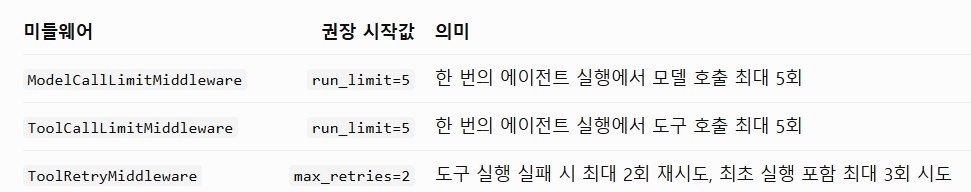

그래프를 그려 보면 `ModelCallLimitMiddleware.before_model` 같은 **훅 노드**가 model 앞뒤에 끼어든 것이 보입니다. 하지만 일을 하는 노드는 여전히 **model과 tools 둘뿐**이고, 미들웨어를 몇 개 붙여도 이 뼈대는 바뀌지 않습니다.

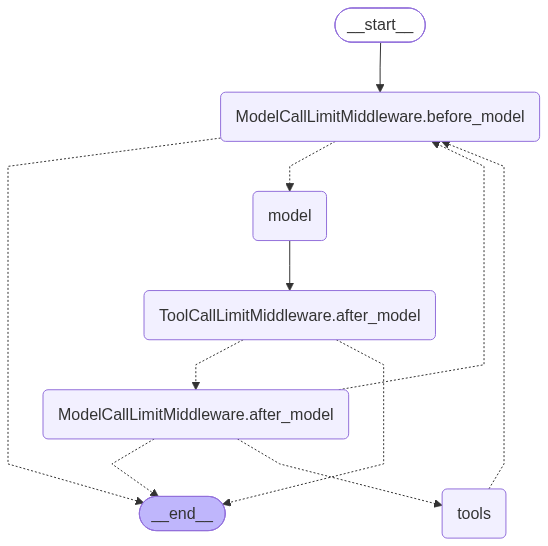

In [27]:
show_graph(middleware_agent)

### 기능별 비교

| 기능 | 미들웨어로 되는 범위 | LangGraph가 필요해지는 경우 |
|---|---|---|
| **분기** | `jump_to`로 model / tools / end 이동, 모델·도구 동적 교체 | 업무 단계가 여러 개라 "A → 조건에 따라 B 또는 C"로 갈 때 (예제 ②) |
| **반복** | model ⇄ tools 루프, 호출 횟수 제한, 도구 재시도 | 반복 조건을 **코드**가 정할 때 (예제 ⑤ 점수 미달이면 다시 쓰기) |
| **병렬** | LLM이 한 턴에 여러 도구를 동시 호출 | 실행 중 개수가 정해지는 작업을 나눠 돌리고 **별도 집계 단계**로 모을 때 (예제 ④ `Send` + 리듀서) |
| **기억** | 체크포인터, `SummarizationMiddleware`, `state_schema` | `messages` 외에 여러 노드가 나눠 쓰는 State와 키별 리듀서가 필요할 때 |
| **사람 승인** | `HumanInTheLoopMiddleware` — **도구 호출 직전** 승인·수정·거부 | 도구가 아닌 지점에서 멈출 때 (초안 검토, 단계별 결재), State 수정·과거 시점 되돌리기 (예제 ⑤) |

### LangGraph가 꼭 필요한 대표 상황
1. **LLM이 아니라 업무 규칙이 흐름을 정해야 할 때**: 프롬프트로 맡기면 LLM이 단계를 건너뛰거나 도구 대신 직접 답해 버릴 수 있습니다.
2. **역할이 다른 에이전트 여러 개를 엮을 때**: 감독자·파이프라인·리뷰 위원회 (예제 ①③④)
3. **LLM이 없는 단계가 섞여 있을 때**: DB 조회, 파일 변환, 검증, 알림 발송
4. **노드마다 다른 운영 정책이 필요할 때**: 노드별 `RetryPolicy`, 타임아웃, 캐시, `error_handler`, 서브그래프
5. **오래 걸리고 중간에 끊겨도 이어가야 할 때**: 며칠에 걸친 승인 흐름, 특정 단계부터 재실행

### 판단 기준
> **다음에 무엇을 할지 LLM이 정한다** → `create_agent()` + 미들웨어 \
> **다음에 무엇을 할지 코드(업무 규칙)가 정한다** → LangGraph

실무에서 가장 흔한 구조는 <span style="color:red">**바깥 흐름은 LangGraph, 각 단계의 똑똑한 일꾼은 create_agent()**</span> 입니다. 예제 ③이 바로 이 조합입니다.

---
### 마무리: 멀티 에이전트 개발 체크리스트

| 질문 | 관련 예제 | 해결 도구 |
|---|---|---|
| 에이전트끼리 결과를 어떻게 주고받나? | ① | 공유 State, 노드는 바뀐 키만 반환 |
| 어떤 에이전트에게 맡길지 어떻게 정하나? | ② ③ | 구조화 출력 + 조건부 엣지 / `Command` |
| 에이전트가 외부 기능을 쓰게 하려면? | ③ | `@tool`, `create_agent` |
| 각 에이전트에게 무엇을 보여줄까? | ① ③ | 컨텍스트 격리 (작업 지시만 전달, 최종 보고만 기록) |
| 무한 루프는 어떻게 막나? | ③ ⑤ | 단계 카운터, 최대 횟수 상한 |
| 여러 에이전트를 동시에 돌리려면? | ④ | `Send` + 리듀서(`operator.add`) |
| 품질을 스스로 높이게 하려면? | ⑤ | 생성자·평가자 분리, 서로 다른 모델 사용 |
| 사람이 중간에 확인하려면? | ⑤ | 체크포인터 + `thread_id` + `interrupt` / `Command(resume)` |
| API 오류에 대비하려면? | ⑤ | `RetryPolicy` |
| 진행 상황을 보여주려면? | ⑤ | `stream(stream_mode="updates")` |
| 단일 루프 에이전트를 짧게 만들려면? | 정리 | `create_agent` + 미들웨어 (`ModelCallLimit`, `ToolCallLimit`, `ToolRetry`) |
| 도구 실패를 어떻게 알리나? | 정리 | 빈 값이 아니라 `ToolException` 예외로 |
| create_agent() 와 LangGraph 중 무엇을? | 정리 | LLM이 흐름을 정하면 create_agent(), 코드가 정하면 LangGraph |

##### 모델 분업 요약
- **gpt-4o-mini**: 라우터, 감독자, 계산 에이전트, 비평가, 종합 — *정확한 형식과 판단*
- **gemini-3.5-flash-lite**: 작성자, 글쓰기/상담 전문가, 여행 도우미, 리뷰어 일부 — *빠르고 저렴한 생성*

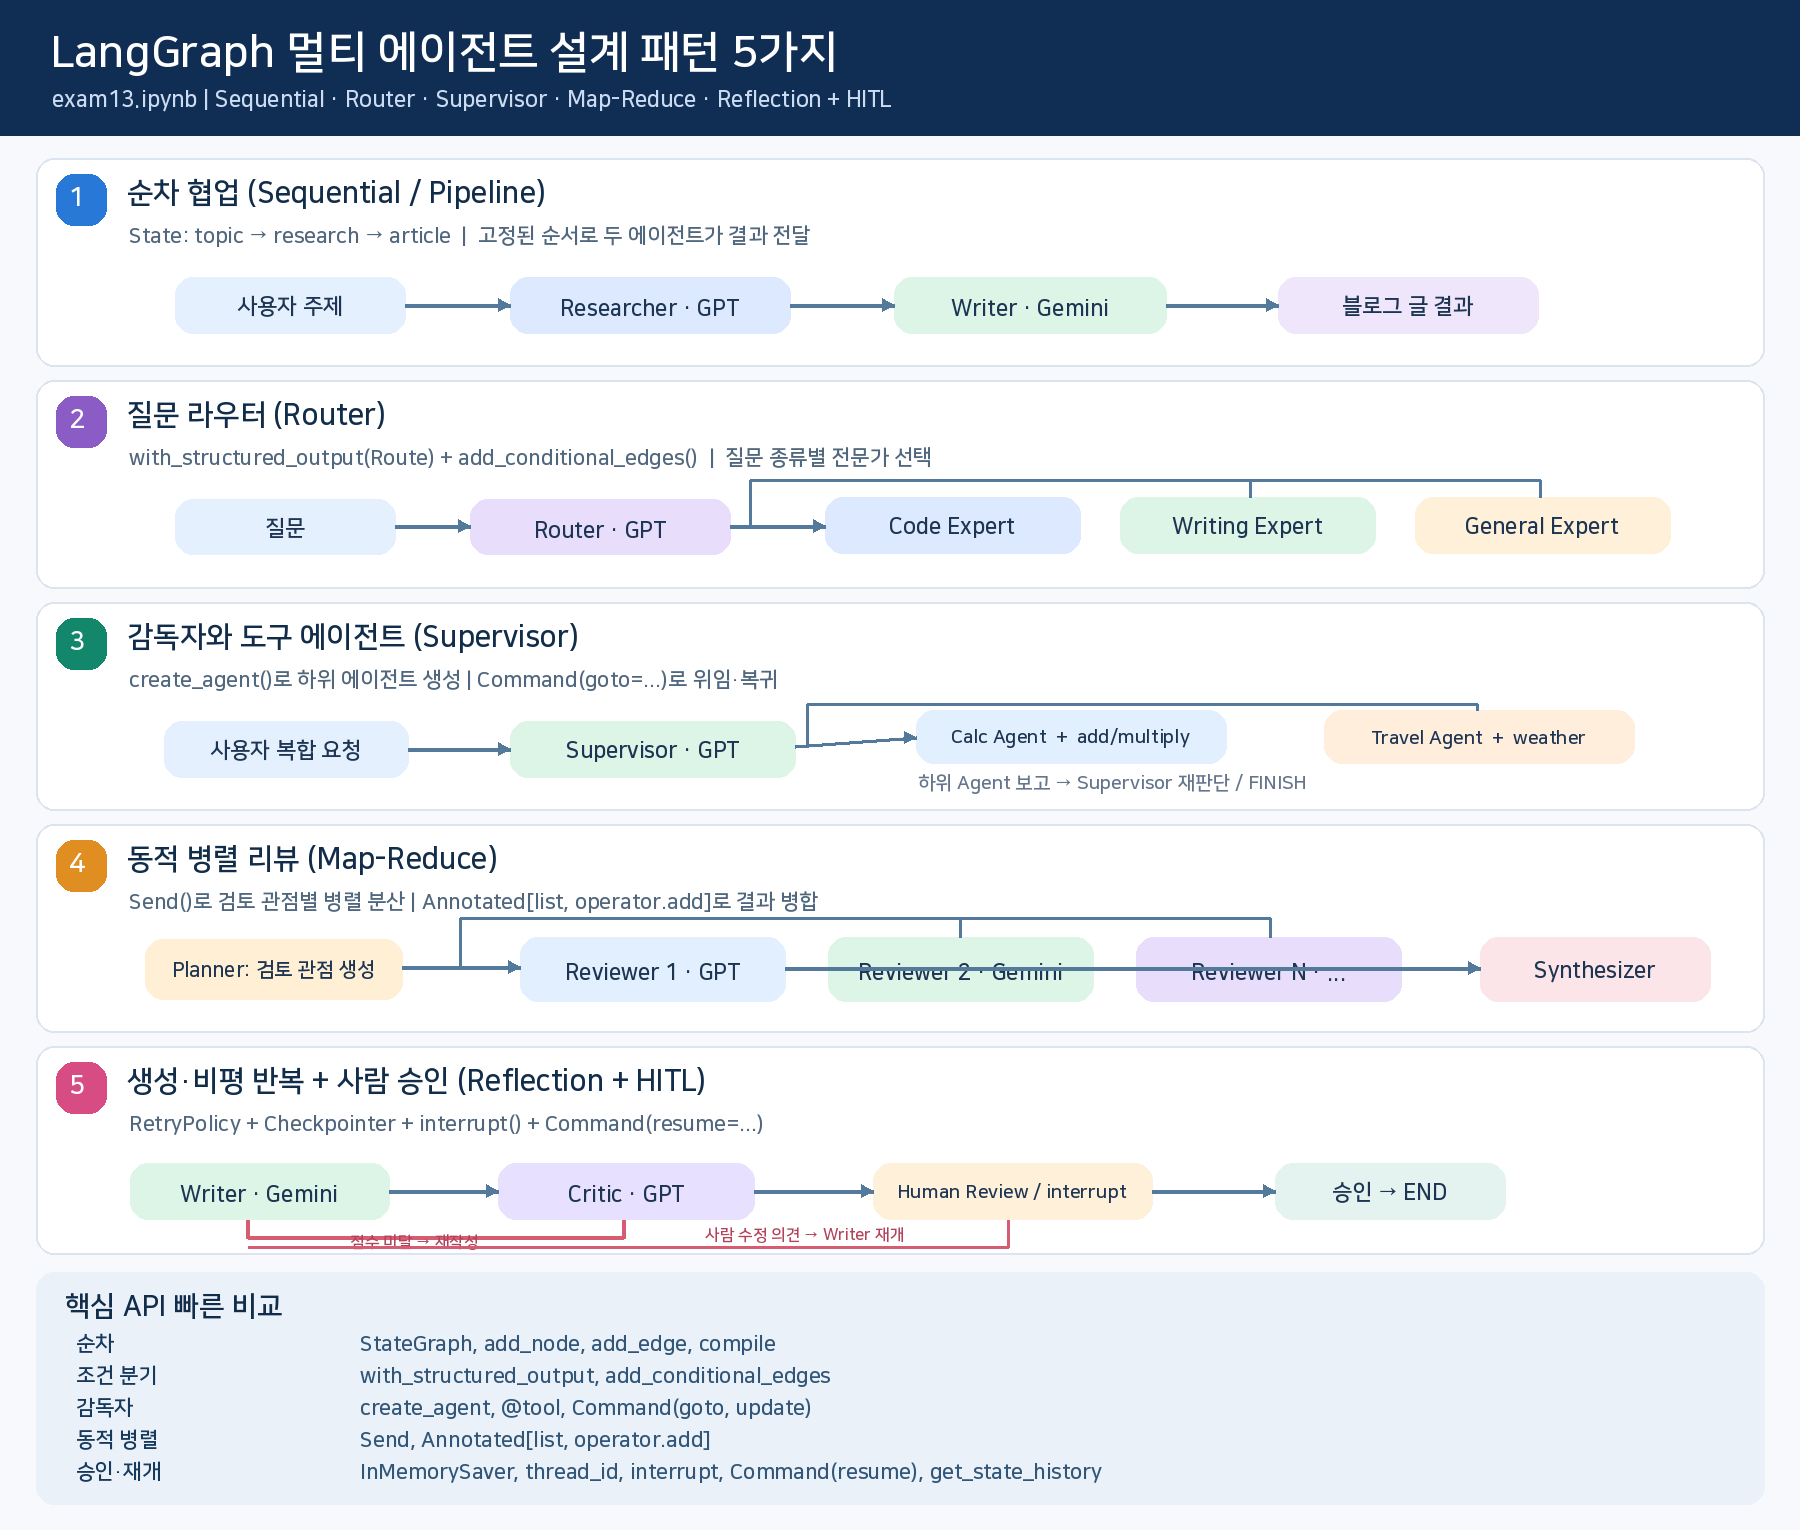

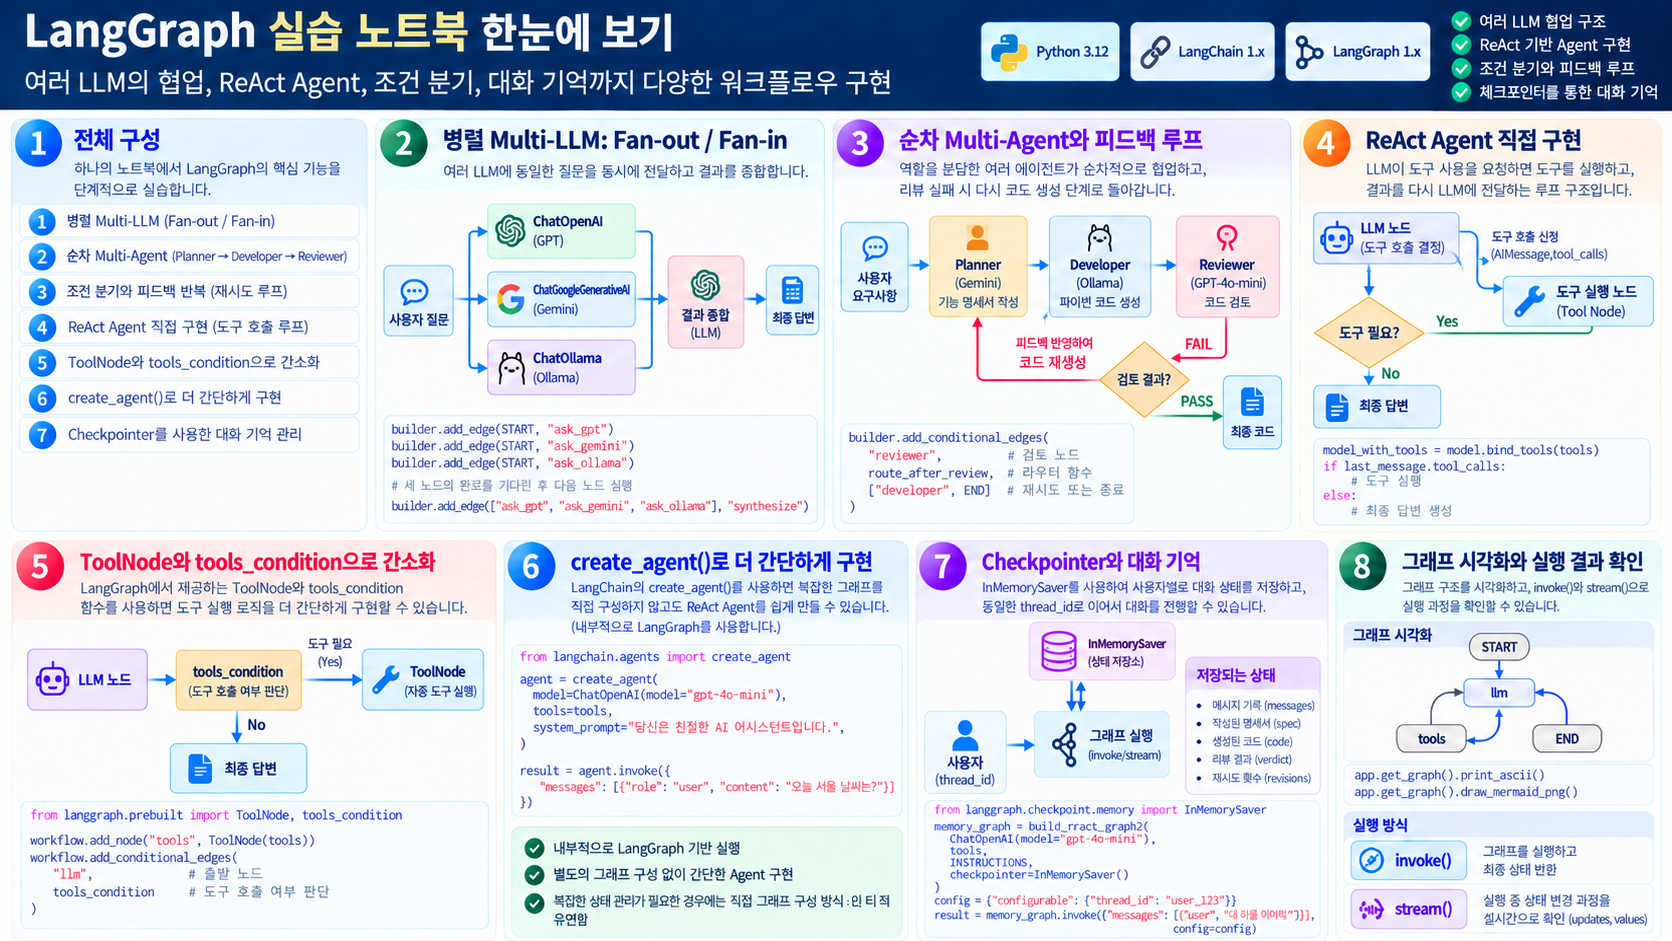

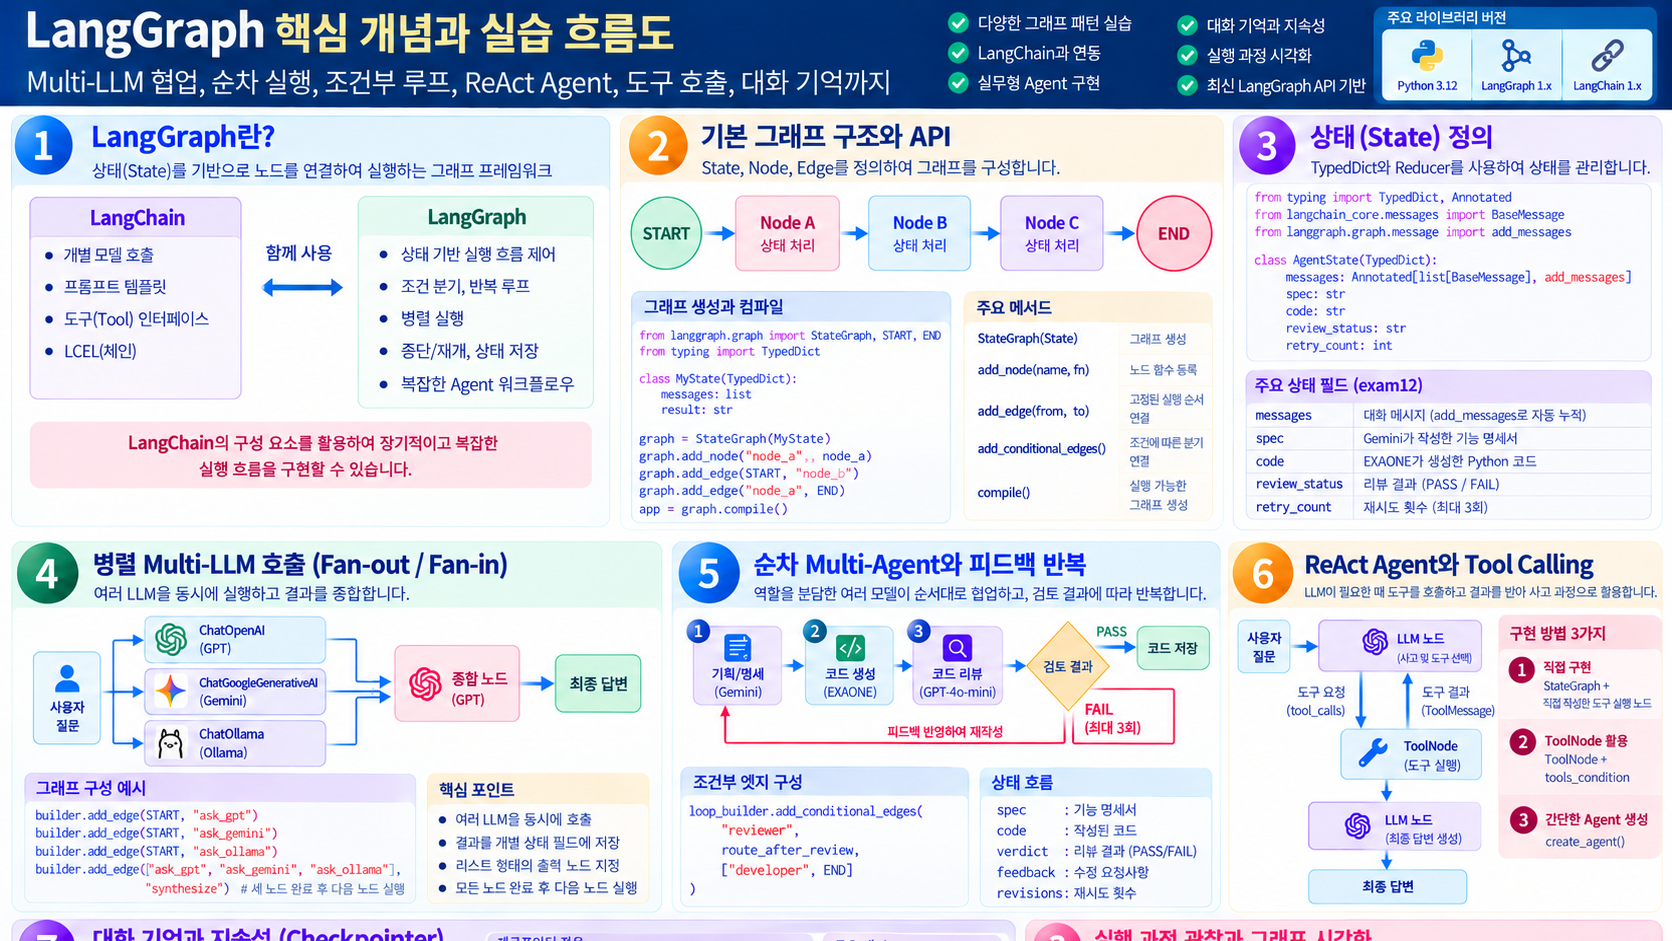

## 🔁 복습 질문

<details>
<summary>1. 감독자 패턴에서 엣지를 거의 그리지 않아도 되는 이유는?</summary>

노드가 `Command(goto=..., update=...)`로 다음 목적지를 직접 정하기 때문이다. 반환 타입 `Command[Literal[...]]`을 적어야 그림에 나타난다.
</details>

<details>
<summary>2. <code>Send</code> 병렬 결과를 한 리스트에 모으려면?</summary>

`Annotated[list[str], operator.add]` 리듀서가 필요하다.
</details>

<details>
<summary>3. <code>interrupt()</code>로 멈춘 그래프를 이어서 실행하려면?</summary>

같은 `thread_id` config로 `Command(resume=사람의 답)`을 넘긴다. 체크포인터가 있어야 한다.
</details>
